## 1️⃣ Initial Setup and Dataset Loading

**Task**: Load the Flickr8k dataset and prepare image-caption pairs for training.

**Requirements**:
- Download and organize the Flickr8k dataset
- Load image files and corresponding captions
- Create proper dataset splits (train/dev/test)
- Set up image transformations and text tokenizationnization

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import kagglehub
import os
from collections import defaultdict
from transformers import AutoTokenizer
import random  # Needed for randomly selecting a caption
from torch.optim import AdamW
from transformers import get_cosine_schedule_with_warmup
from torchvision.models import resnet50 # Import resnet50
from torchvision.models import ResNet50_Weights
resnet50(weights=ResNet50_Weights.DEFAULT)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)
np.random.seed(42)

path = kagglehub.dataset_download("ming666/flicker8k-dataset")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 125MB/s]


In [2]:

captions_file = os.path.join(path, "Flickr8k_text", "Flickr8k.token.txt")

# {"image_name.jpg": ["caption1", "caption2", ...]}
image_captions = defaultdict(list)

with open(captions_file, 'r') as f:
    for line in f:
        img_caption = line.strip().split('\t')
        img_name, caption = img_caption[0].split('#')[0], img_caption[1]
        image_captions[img_name].append(caption)


In [3]:
def load_split(split_file):
    with open(split_file, 'r') as f:
        return [line.strip() for line in f.readlines()]

train_imgs = load_split(os.path.join(path, "Flickr8k_text", "Flickr_8k.trainImages.txt"))
val_imgs = load_split(os.path.join(path, "Flickr8k_text", "Flickr_8k.devImages.txt"))
test_imgs = load_split(os.path.join(path, "Flickr8k_text", "Flickr_8k.testImages.txt"))


In [4]:

img_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),
])

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [5]:
# Define custom dataset for Flickr8k
class FlickrDataset(Dataset):
    def __init__(self, img_list, captions_dict, img_dir, tokenizer, transform):
        """
        Args:
            img_list (List[str]): List of image file names (e.g., '1000092795.jpg')
            captions_dict (Dict[str, List[str]]): Dictionary mapping image names to list of captions
            img_dir (str): Path to directory containing image files
            tokenizer (AutoTokenizer): BERT tokenizer to encode captions
            transform (callable): torchvision transform to apply to images
        """
        self.img_list = img_list
        self.captions = captions_dict
        self.img_dir = img_dir
        self.tokenizer = tokenizer
        self.transform = transform

    def __len__(self):
        # Return the number of samples in the dataset
        return len(self.img_list)

    def __getitem__(self, idx):
        # Get image file name
        img_name = self.img_list[idx]

        # Randomly select one caption for the image (instead of always using the first one)
        caption = random.choice(self.captions[img_name])

        # Load and preprocess image
        img_path = os.path.join(self.img_dir, img_name)
        image = self.transform(Image.open(img_path).convert('RGB'))

        # Tokenize the selected caption using the BERT tokenizer
        tokens = self.tokenizer(
            caption,
            padding='max_length',      # pad to max_length
            truncation=True,           # truncate if longer than max_length
            max_length=30,             # fixed length for input
            return_tensors="pt"        # return PyTorch tensors
        )

        # Return dictionary containing image tensor and tokenized caption
        return {
            "image": image,  # shape: [3, 224, 224]
            "input_ids": tokens['input_ids'].squeeze(0),         # shape: [30]
            "attention_mask": tokens['attention_mask'].squeeze(0)  # shape: [30]
        }


In [6]:
# Define the folder path where the images are stored
image_folder = os.path.join(path, "Flickr8k_Dataset", "Flicker8k_Dataset")

train_data = FlickrDataset(train_imgs, image_captions, image_folder, tokenizer, img_transform)
val_data = FlickrDataset(val_imgs, image_captions, image_folder, tokenizer, img_transform)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32)


## 2️⃣ CLIP Model Architecture Implementation

**Task**: Implement the dual-encoder CLIP architecture with pretrained backbones.

**Requirements**:
- Create ImageEncoder using pretraa pre trained model, for example ResNet-50
- Create TextEncoder using pretrfor example DistilBERT
- Implement projection layers to shared embedding space
- Build complete CLIP model with learnable temperature parameter
- Define contrastive loss function for trainingle values

In [7]:
# Image Encoder using ResNet-50
class ImageEncoder(nn.Module):
    def __init__(self, embed_dim):
        super().__init__()
        # ResNet50
        backbone = resnet50(pretrained=True)
        self.backbone = nn.Sequential(*list(backbone.children())[:-1])  # remove final FC
        self.projection = nn.Linear(2048, embed_dim)  # map to shared embedding space

    def forward(self, images):
        with torch.no_grad():
            features = self.backbone(images).squeeze()  # [B, 2048, 1, 1] -> [B, 2048]
        # Projection to shared embedding space
        projected = self.projection(features)
        return F.normalize(projected, dim=-1)

class TextEncoder(nn.Module):
    def __init__(self, embed_dim):
        super().__init__()
        self.backbone = DistilBertModel.from_pretrained("distilbert-base-uncased")
        self.projection = nn.Linear(self.backbone.config.hidden_size, embed_dim)

    def forward(self, input_ids, attention_mask):
        with torch.no_grad():
            outputs = self.backbone(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0]  # [CLS] token
        projected = self.projection(cls_embedding)
        return F.normalize(projected, dim=-1)
# CLIP Dual Encoder Model
class CLIPModel(nn.Module):
    def __init__(self, embed_dim=256):
        super().__init__()
        self.image_encoder = ImageEncoder(embed_dim)
        self.text_encoder = TextEncoder(embed_dim)
        self.logit_scale = nn.Parameter(torch.ones([]) * torch.log(torch.tensor(1/0.07)))

    def forward(self, images, input_ids, attention_mask):
        image_embeds = self.image_encoder(images)        # [B, D]
        text_embeds = self.text_encoder(input_ids, attention_mask)  # [B, D]

        # Scale
        scale = self.logit_scale.exp()
        logits_per_image = image_embeds @ text_embeds.t() * scale
        logits_per_text = logits_per_image.t()

        return logits_per_image, logits_per_text
# Contrastive Loss Function
def contrastive_loss(logits_per_image, logits_per_text):
    """
    Computes average cross-entropy loss between image-text pairs
    """
    batch_size = logits_per_image.size(0)
    labels = torch.arange(batch_size, device=logits_per_image.device)
    # Cross entropy for both directions
    loss_i = F.cross_entropy(logits_per_image, labels)
    loss_t = F.cross_entropy(logits_per_text, labels)
    return (loss_i + loss_t) / 2

## 3️⃣ Model Training with Contrastive Learning

**Task**: Train the CLIP model using contrastive learning objective.

**Requirements**:
- Implement training loop with proper optimization
- Use cosine learning rate scheduling with warmup
- Track training and validation metrics
- Implement periodic evaluation during training
- Monitor convergence and model performance

In [8]:
from torch.optim import AdamW
from transformers import get_cosine_schedule_with_warmup

def build_optimizer(model, train_dataloader, epochs=10, lr=5e-5, warmup_steps=500):
    """
    Build optimizer and learning rate scheduler for training.
    - AdamW is used for better weight decay handling (common for transformers)
    - Cosine schedule with warmup gradually increases LR at the start,
      then decays following a cosine curve.
    """
    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

    # Total number of optimization steps for all epochs
    total_steps = len(train_dataloader) * epochs

    # Cosine schedule with warmup steps
    scheduler = get_cosine_schedule_with_warmup(
        optimizer,
        num_warmup_steps=warmup_steps,
        num_training_steps=total_steps
    )

    return optimizer, scheduler


def train_one_epoch(model, dataloader, optimizer, scheduler):
    """
    Train the model for one full epoch.
    - Sets model to training mode
    - Loops over all batches
    - Computes loss using contrastive learning
    - Updates model weights and learning rate
    - Returns average training loss
    """
    model.train()
    total_loss = 0

    for batch in dataloader:
        # Move batch data to device (GPU/CPU)
        images = batch['image'].to(device)
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)

        # Forward pass through CLIP
        logits_img, logits_txt = model(images, input_ids, attention_mask)

        # Compute contrastive loss
        loss = contrastive_loss(logits_img, logits_txt)

        # Backpropagation + optimizer step
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

    # Return average loss over all batches
    return total_loss / len(dataloader)


@torch.no_grad()
def evaluate(model, dataloader):
    """
    Evaluate the model without gradient updates.
    - Sets model to evaluation mode
    - Loops over validation data
    - Computes average validation loss
    """
    model.eval()
    total_loss = 0

    for batch in dataloader:
        images = batch['image'].to(device)
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)

        logits_img, logits_txt = model(images, input_ids, attention_mask)
        loss = contrastive_loss(logits_img, logits_txt)

        total_loss += loss.item()

    return total_loss / len(dataloader)


def train_model(model, train_loader, val_loader, epochs=10):
    """
    Full training loop over multiple epochs.
    - Trains and evaluates at each epoch
    - Tracks the best validation loss
    - Saves the model whenever it achieves a new best val loss
    """
    optimizer, scheduler = build_optimizer(model, train_loader, epochs)
    best_val_loss = float('inf')  # initialize best loss as infinity

    for epoch in range(1, epochs+1):
        # Train for one epoch
        train_loss = train_one_epoch(model, train_loader, optimizer, scheduler)

        # Validate after epoch
        val_loss = evaluate(model, val_loader)

        # Log results
        print(f"Epoch {epoch:02d} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

        # Save the best model so far
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), "best_clip_model.pt")
            print("Saved new best model")

## 4️⃣ Training Visualization and Performance Analysis

**Task**: Visualize training progress and analyze model convergence.

**Requirements**:
- Plot training and validation loss curves
- Display accuracy progression over epochs  
- Analyze learning dynamics and convergence patterns

In [9]:

from transformers import DistilBertModel



def compute_accuracy(logits_per_image):
    # Accuracy
    targets = torch.arange(logits_per_image.size(0)).to(logits_per_image.device)
    preds = logits_per_image.argmax(dim=1)
    correct = (preds == targets).sum().item()
    return correct / logits_per_image.size(0)
def train_one_epoch(model, dataloader, optimizer, scheduler):
    model.train()
    total_loss, total_acc = 0, 0 # for i

    for batch in dataloader:
        images = batch['image'].to(device)
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)

        logits_img, logits_txt = model(images, input_ids, attention_mask)
        loss = contrastive_loss(logits_img, logits_txt)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        total_acc += compute_accuracy(logits_img)

    avg_loss = total_loss / len(dataloader)
    avg_acc = total_acc / len(dataloader)
    return avg_loss, avg_acc

@torch.no_grad()
def evaluate(model, dataloader):
    model.eval()
    total_loss, total_acc = 0, 0

    for batch in dataloader:
        images = batch['image'].to(device)
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)

        logits_img, logits_txt = model(images, input_ids, attention_mask)
        loss = contrastive_loss(logits_img, logits_txt)

        total_loss += loss.item()
        total_acc += compute_accuracy(logits_img)

    avg_loss = total_loss / len(dataloader)
    avg_acc = total_acc / len(dataloader)
    return avg_loss, avg_acc

def train_model(model, train_loader, val_loader, epochs=10):
    optimizer, scheduler = build_optimizer(model, train_loader, epochs)

    train_losses, val_losses = [], []
    train_accs, val_accs = [], []

    best_val_loss = float('inf')

    print(f"\n Starting training for {epochs} epochs...\n")

    for epoch in range(1, epochs+1):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, scheduler)
        val_loss, val_acc = evaluate(model, val_loader)

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accs.append(train_acc)
        val_accs.append(val_acc)

        print(f"Epoch {epoch:02d} | Train Loss: {train_loss:.4f} | Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} | Acc: {val_acc:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), "best_clip_model.pt")
            print("Saved new best model!")

    return train_losses, val_losses, train_accs, val_accs


model = CLIPModel(embed_dim=256).to(device)


train_losses, val_losses, train_accs, val_accs = train_model(
    model, train_loader, val_loader, epochs=10
)

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 172MB/s]


model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]


 Starting training for 10 epochs...

Epoch 01 | Train Loss: 3.4393 | Acc: 0.0582 | Val Loss: 3.1894 | Acc: 0.1328
Saved new best model!
Epoch 02 | Train Loss: 2.7435 | Acc: 0.2000 | Val Loss: 2.1729 | Acc: 0.3184
Saved new best model!
Epoch 03 | Train Loss: 2.1527 | Acc: 0.3133 | Val Loss: 1.8669 | Acc: 0.4102
Saved new best model!
Epoch 04 | Train Loss: 1.8897 | Acc: 0.3956 | Val Loss: 1.6864 | Acc: 0.4590
Saved new best model!
Epoch 05 | Train Loss: 1.7653 | Acc: 0.4252 | Val Loss: 1.6582 | Acc: 0.4639
Saved new best model!
Epoch 06 | Train Loss: 1.6663 | Acc: 0.4571 | Val Loss: 1.5989 | Acc: 0.4883
Saved new best model!
Epoch 07 | Train Loss: 1.6021 | Acc: 0.4802 | Val Loss: 1.5623 | Acc: 0.5049
Saved new best model!
Epoch 08 | Train Loss: 1.5512 | Acc: 0.4972 | Val Loss: 1.4998 | Acc: 0.5264
Saved new best model!
Epoch 09 | Train Loss: 1.5640 | Acc: 0.4884 | Val Loss: 1.5119 | Acc: 0.5068
Epoch 10 | Train Loss: 1.5270 | Acc: 0.5038 | Val Loss: 1.5481 | Acc: 0.5137


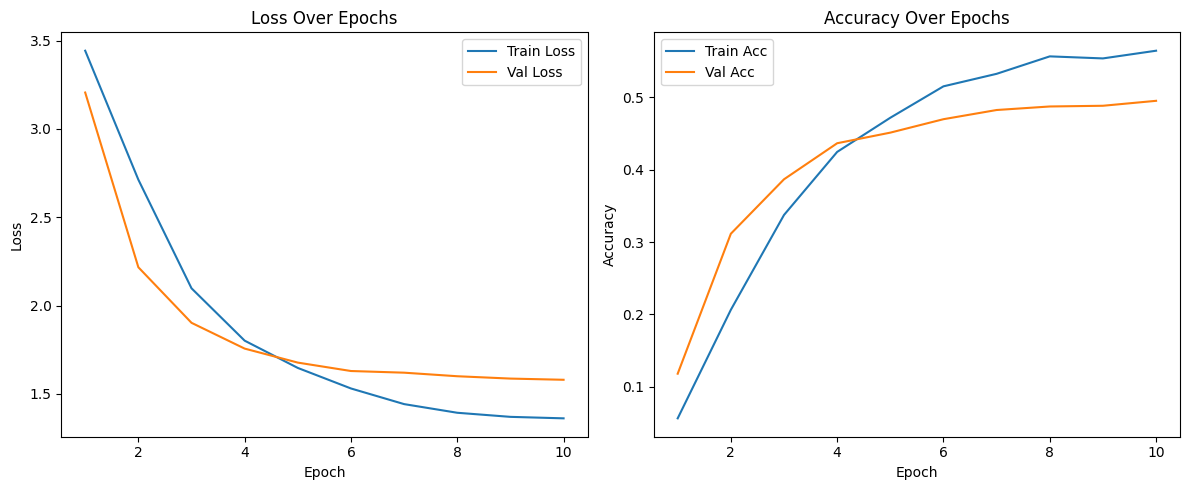

In [ ]:
import matplotlib.pyplot as plt

def plot_metrics(train_losses, val_losses, train_accs, val_accs):
    epochs = range(1, len(train_losses)+1)

    plt.figure(figsize=(12, 5))

    # Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_losses, label="Train Loss")
    plt.plot(epochs, val_losses, label="Val Loss")
    plt.title("Loss Over Epochs")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    # Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_accs, label="Train Acc")
    plt.plot(epochs, val_accs, label="Val Acc")
    plt.title("Accuracy Over Epochs")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.tight_layout()
    plt.show()
plot_metrics(train_losses, val_losses, train_accs, val_accs)


## 5️⃣ Zero-Shot Classification Implementation

**Task**: Implement and test zero-shot classification capabilities using the trained CLIP model.

**Requirements**:
- Create zero-shot classification function
- Define text prompts for different categories
- Test on sample images from the test set
- Calculate similarities and make predictions
- Visualize classification results with confidence scores

Hard Prompting Prediction Results:
child                          -> 0.1379
walking                        -> 0.1344
people outdoors                -> 0.1321
water or beach                 -> 0.1321
person                         -> 0.1220
nature                         -> 0.1174
dog                            -> 0.1137
animals                        -> 0.1104


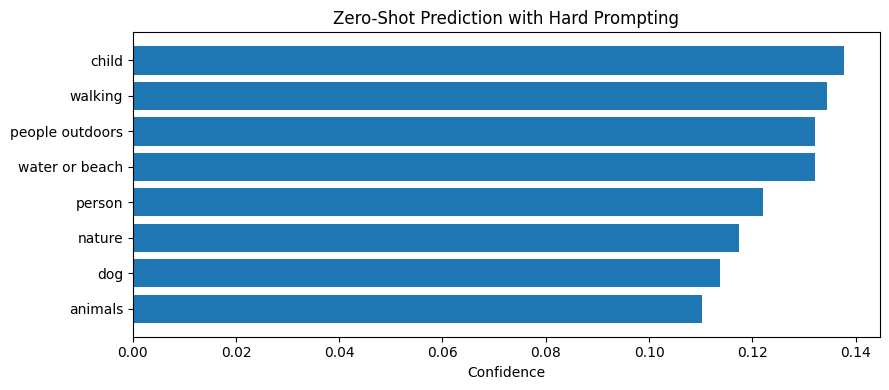

In [18]:
# Zero-Shot Classification with Hard Prompting
@torch.no_grad()
def zero_shot_classify_hard_prompting(model, image_tensor, category_prompts):
    """
    Zero-shot classification using Hard Prompting (multiple prompts per class).
    For each category, we encode several prompt variations and average their embeddings
    to get a robust class representation. Then we compare the image embedding against
    these averaged class embeddings.

    Args:
        model: Trained CLIP model (with .image_encoder and .text_encoder).
        image_tensor: Single image tensor of shape [1, C, H, W].
        category_prompts: dict[str, list[str]] mapping class name -> list of prompt strings.
    """
    model.eval()

    # Ensure shape [1, C, H, W] and move to device
    if image_tensor.dim() == 3:
        image_tensor = image_tensor.unsqueeze(0)
    image_tensor = image_tensor.to(device)

    # Compute image embedding
    image_embed = model.image_encoder(image_tensor)  # [1, D]
    if image_embed.dim() == 1:
        image_embed = image_embed.unsqueeze(0)       # force [1, D]

    # Build averaged text embeddings per category
    category_names = []
    category_embeds = []

    for category, prompts in category_prompts.items():
        tokens = tokenizer(
            prompts,
            padding='max_length',
            truncation=True,
            max_length=30,
            return_tensors='pt'
        ).to(device)

        text_embeds = model.text_encoder(tokens['input_ids'], tokens['attention_mask'])  # [num_prompts, D]
        avg_embed = text_embeds.mean(dim=0)  # [D]
        category_names.append(category)
        category_embeds.append(avg_embed)

    category_embeds = torch.stack(category_embeds, dim=0)  # [C, D]

    # Similarity + softmax
    logits = image_embed @ category_embeds.T  # [1, C]
    probs = F.softmax(logits, dim=1).squeeze(0)  # [C]

    # Sort and display
    sorted_probs, indices = probs.sort(descending=True)

    print("Hard Prompting Prediction Results:")
    for i in range(len(category_names)):
        print(f"{category_names[indices[i]]:<30} -> {sorted_probs[i].item():.4f}")

    # Visualization
    plt.figure(figsize=(9, 4))
    sorted_categories = [category_names[i] for i in indices.tolist()]
    sorted_confidence = [sorted_probs[i].item() for i in range(len(category_names))]
    plt.barh(sorted_categories[::-1], sorted_confidence[::-1])
    plt.xlabel("Confidence")
    plt.title("Zero-Shot Prediction with Hard Prompting")
    plt.tight_layout()
    plt.show()


# Example hard-prompt sets per category
# Expanded Hard-Prompt Sets with More Variations
hard_prompt_categories = {
    "dog": [
        "a photo of a dog",
        "a dog playing in the park",
        "a close-up picture of a dog",
        "an animal with fur that barks",
        "a domestic dog sitting on the grass",
        "a playful puppy running around",
        "a brown and white dog with floppy ears",
        "a happy dog wagging its tail"
    ],
    "person": [
        "a photo of a person",
        "a man or woman standing",
        "a human in the image",
        "a person wearing casual clothes",
        "a portrait photo of a person smiling",
        "a person holding something in their hand",
        "a full-body shot of a human",
        "a close-up image of a person's face"
    ],
    "child": [
        "a photo of a child",
        "a young kid playing outdoors",
        "a little boy or girl smiling",
        "a child running on grass",
        "a happy child holding a toy",
        "a child wearing colorful clothes",
        "a young child with curly hair",
        "a laughing child in a playground"
    ],
    "people outdoors": [
        "a photo of people outdoors",
        "a group of people outside in nature",
        "people walking together outside",
        "people in an open outdoor scene",
        "friends enjoying time in a park",
        "a group of hikers in the mountains",
        "people standing under the sunlight",
        "a crowd of people at an outdoor event"
    ],
    "water or beach": [
        "a photo of water or beach",
        "people at the beach near the ocean",
        "waves and sand by the sea",
        "someone walking near water",
        "a tropical beach with palm trees",
        "a clear blue sea on a sunny day",
        "a family playing on the shoreline",
        "people swimming in the ocean"
    ],
    "animals": [
        "a photo of animals",
        "multiple animals in the scene",
        "wild animals in nature",
        "a group of animals outdoors",
        "a herd of animals grazing in a field",
        "two or more animals together",
        "farm animals like cows and sheep",
        "exotic animals in a natural habitat"
    ],
    "walking": [
        "a photo of someone walking",
        "a person walking on a path",
        "a human in motion taking a walk",
        "a person walking outside",
        "a person walking in the park",
        "a hiker walking in the mountains",
        "a runner jogging on a trail",
        "a person walking their dog"
    ],
    "nature": [
        "a photo of nature",
        "a beautiful natural landscape with trees",
        "greenery and plants in the wild",
        "a scenic view of mountains and trees",
        "a peaceful forest with sunlight",
        "a river flowing through nature",
        "snow-capped mountains under blue skies",
        "flowers blooming in a meadow"
    ],
}


# Run on a sample image from the validation loader
sample_batch = next(iter(val_loader))
sample_image = sample_batch['image'][0].unsqueeze(0)  # [1, C, H, W]

zero_shot_classify_hard_prompting(model, sample_image, hard_prompt_categories)


## 6️⃣ Custom Prompt Testing

**Task**: Test the model with custom text prompts

**Requirements**:
- Create custom text prompts for specific scenarios
- Test model performance on different prompt styles
- Create comprehensive visualization of results

Custom Prompt Classification
----------------------------------------
a child running on grass                 -> 0.1466
a person with a backpack in nature       -> 0.1465
a beautiful landscape scene              -> 0.1333
someone walking near the water           -> 0.1303
two people smiling in sunlight           -> 0.1297
children having fun outdoors             -> 0.1104
a happy dog playing                      -> 0.1085
people at the beach                      -> 0.0947


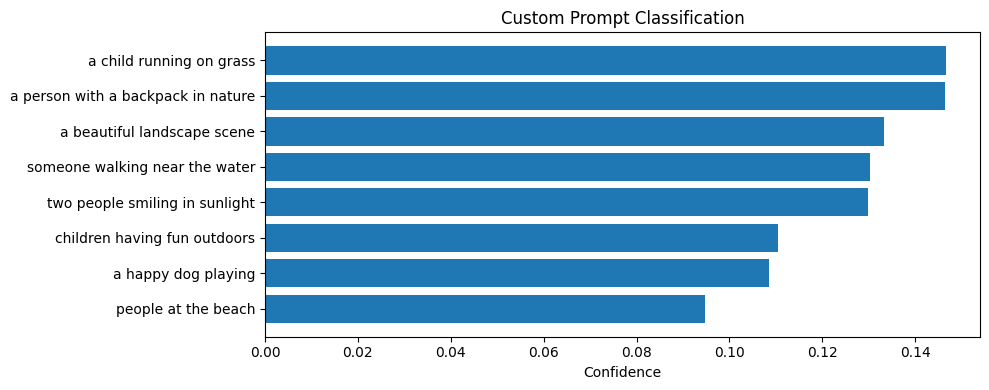

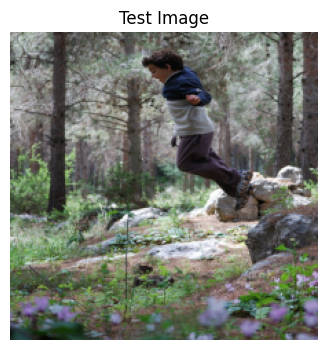

In [19]:
# Custom Prompt Testing (with small fixes)
# Handles image shape [C,H,W] or [1,C,H,W] safely
# Proper un-normalization for visualization
# Same behavior as your version, just more robust
custom_prompts = [
    "a happy dog playing",
    "children having fun outdoors",
    "a beautiful landscape scene",
    "people at the beach",
    "someone walking near the water",
    "a person with a backpack in nature",
    "a child running on grass",
    "two people smiling in sunlight"
]

@torch.no_grad()
def zero_shot_classify(model, image_tensor, prompts, title="Zero-Shot Prediction"):
    """
    Zero-shot classification on a single image against a list of custom prompts.
    - Accepts image_tensor of shape [C,H,W] or [1,C,H,W].
    - Computes image/text embeddings, similarities, and visualizes confidence scores.
    """
    model.eval()

    # Ensure batch dimension exists: if [C,H,W] -> [1,C,H,W]
    if image_tensor.dim() == 3:
        image_tensor = image_tensor.unsqueeze(0)
    image_tensor = image_tensor.to(device)

    # Tokenize all prompts at once
    tokens = tokenizer(
        prompts,
        padding='max_length',
        truncation=True,
        max_length=30,
        return_tensors='pt'
    ).to(device)

    # Forward encoders
    image_embed = model.image_encoder(image_tensor)   # [1, D]
    if image_embed.dim() == 1:                        # safety, enforce 2D
        image_embed = image_embed.unsqueeze(0)

    text_embeds = model.text_encoder(tokens['input_ids'], tokens['attention_mask'])  # [P, D]

    # Similarity and probabilities
    logits = image_embed @ text_embeds.T             # [1, P]
    probs = F.softmax(logits, dim=1).squeeze(0)      # [P]

    # Sort by confidence
    sorted_probs, indices = probs.sort(descending=True)

    # Print ranked predictions
    print(f"{title}")
    print("-" * 40)
    for i in range(len(prompts)):
        print(f"{prompts[indices[i]]:<40} -> {sorted_probs[i].item():.4f}")

    # Visualization (highest on top)
    plt.figure(figsize=(10, 4))
    sorted_categories = [prompts[i] for i in indices.tolist()]
    sorted_confidence = [sorted_probs[i].item() for i in range(len(prompts))]
    plt.barh(sorted_categories[::-1], sorted_confidence[::-1])
    plt.xlabel("Confidence")
    plt.title(title)
    plt.tight_layout()
    plt.show()

# Sample image from validation loader
sample_batch = next(iter(val_loader))
sample_image = sample_batch['image'][1]  # shape [C,H,W] here is fine

# Run zero-shot classification with custom prompts
zero_shot_classify(model, sample_image, custom_prompts, title="Custom Prompt Classification")

def show_image(img_tensor):
    """
    Properly un-normalize and display an ImageNet-normalized tensor:
    input img_tensor: [C,H,W] in range ~N(0,1) after normalization.
    """
    # Convert to numpy HWC
    img = img_tensor.detach().cpu()
    # Unnormalize per-channel using ImageNet stats
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    img = img * std + mean
    img = img.permute(1, 2, 0).numpy()  # [H,W,C]
    img = img.clip(0, 1)

    plt.figure(figsize=(4,4))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Test Image")
    plt.show()

# Visualize the same image used for zero-shot
show_image(sample_image)



--- Image 28 ---


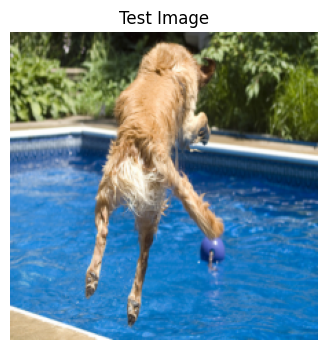

Prediction for Image 28
----------------------------------------
a happy dog playing                      -> 0.1662
a child running on grass                 -> 0.1415
someone walking near the water           -> 0.1250
people at the beach                      -> 0.1186
two people smiling in sunlight           -> 0.1162
children having fun outdoors             -> 0.1132
a person with a backpack in nature       -> 0.1102
a beautiful landscape scene              -> 0.1090


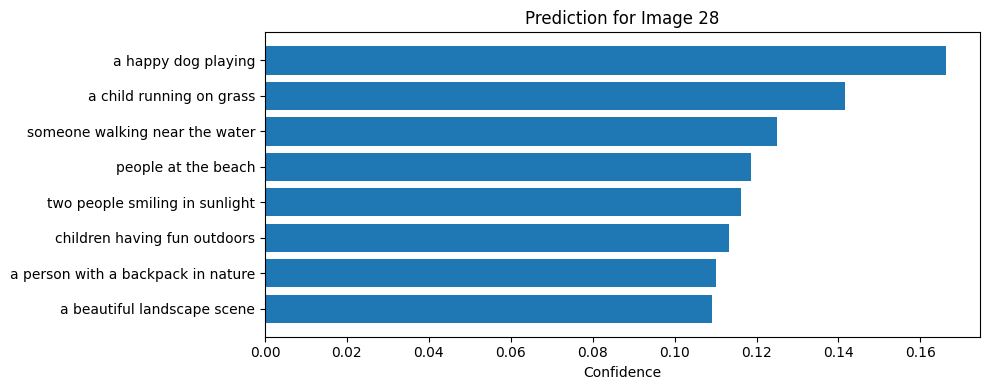


--- Image 18 ---


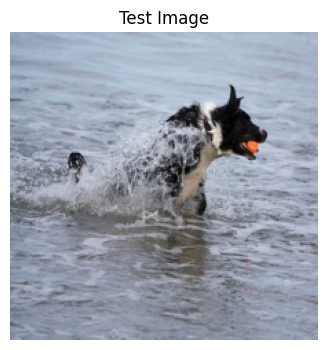

Prediction for Image 18
----------------------------------------
someone walking near the water           -> 0.1515
people at the beach                      -> 0.1393
a happy dog playing                      -> 0.1346
two people smiling in sunlight           -> 0.1323
a child running on grass                 -> 0.1233
a person with a backpack in nature       -> 0.1174
a beautiful landscape scene              -> 0.1072
children having fun outdoors             -> 0.0944


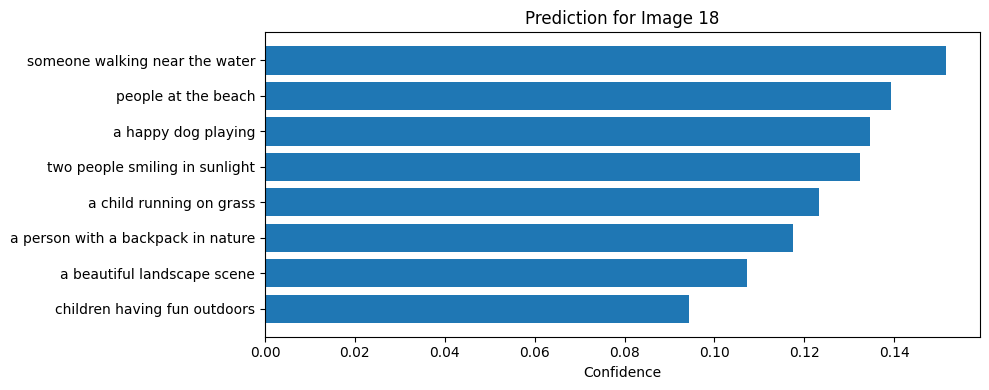


--- Image 3 ---


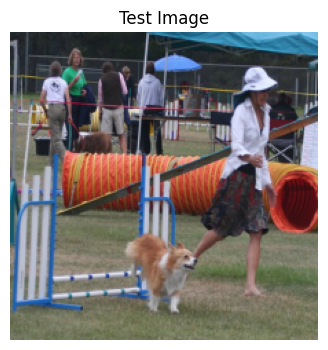

Prediction for Image 3
----------------------------------------
children having fun outdoors             -> 0.1638
a happy dog playing                      -> 0.1547
a child running on grass                 -> 0.1278
a beautiful landscape scene              -> 0.1253
a person with a backpack in nature       -> 0.1174
people at the beach                      -> 0.1110
two people smiling in sunlight           -> 0.1036
someone walking near the water           -> 0.0963


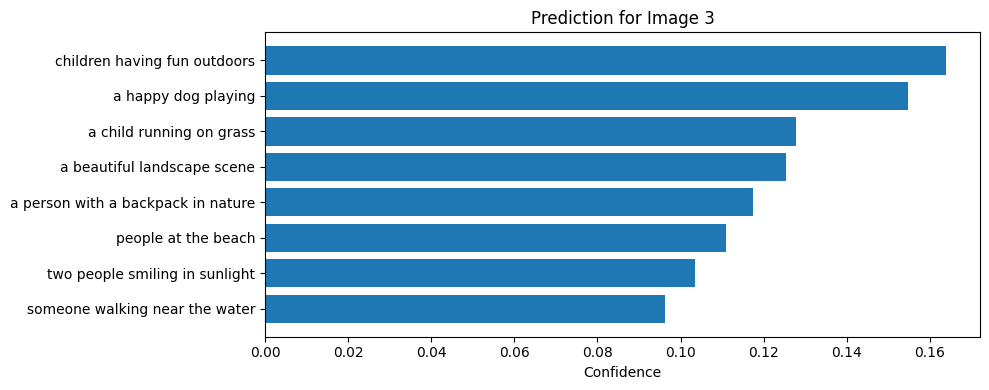


--- Image 32 ---


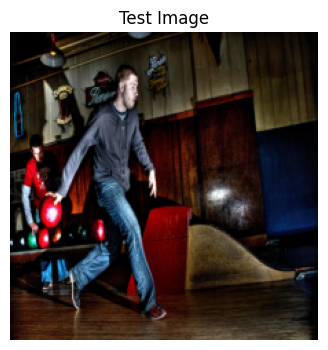

Prediction for Image 32
----------------------------------------
two people smiling in sunlight           -> 0.1356
a happy dog playing                      -> 0.1320
a person with a backpack in nature       -> 0.1304
a child running on grass                 -> 0.1255
a beautiful landscape scene              -> 0.1234
someone walking near the water           -> 0.1217
children having fun outdoors             -> 0.1176
people at the beach                      -> 0.1138


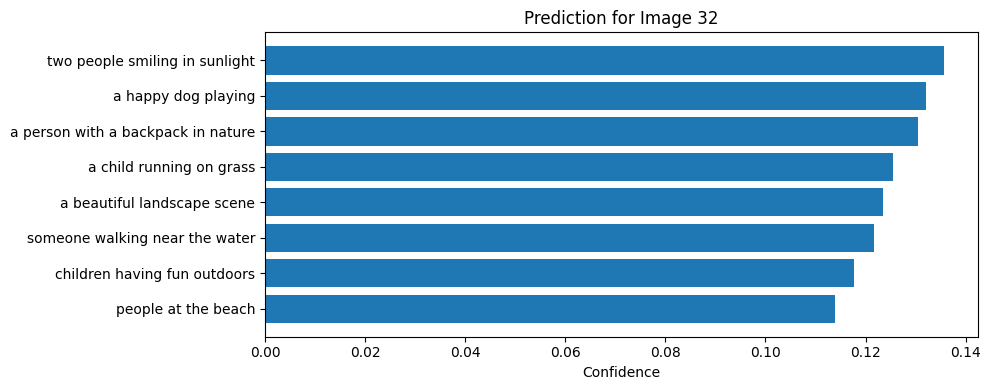


--- Image 2 ---


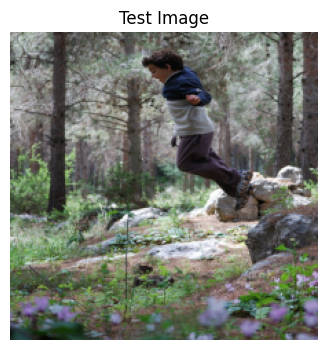

Prediction for Image 2
----------------------------------------
a child running on grass                 -> 0.1466
a person with a backpack in nature       -> 0.1465
a beautiful landscape scene              -> 0.1333
someone walking near the water           -> 0.1303
two people smiling in sunlight           -> 0.1297
children having fun outdoors             -> 0.1104
a happy dog playing                      -> 0.1085
people at the beach                      -> 0.0947


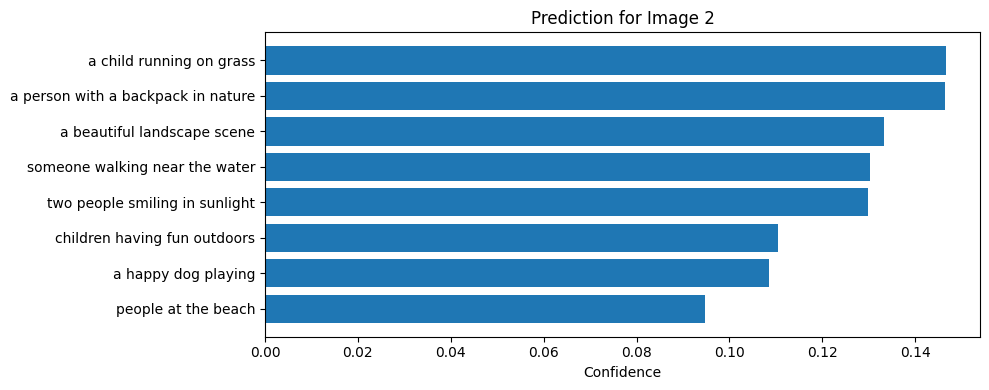


--- External Image 1 ---


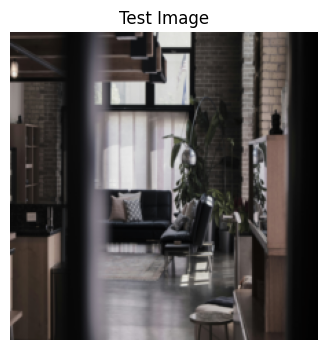

Prediction for External Image 1
----------------------------------------
a beautiful landscape scene              -> 0.1381
someone walking near the water           -> 0.1341
children having fun outdoors             -> 0.1259
two people smiling in sunlight           -> 0.1249
a person with a backpack in nature       -> 0.1235
a happy dog playing                      -> 0.1221
people at the beach                      -> 0.1199
a child running on grass                 -> 0.1115


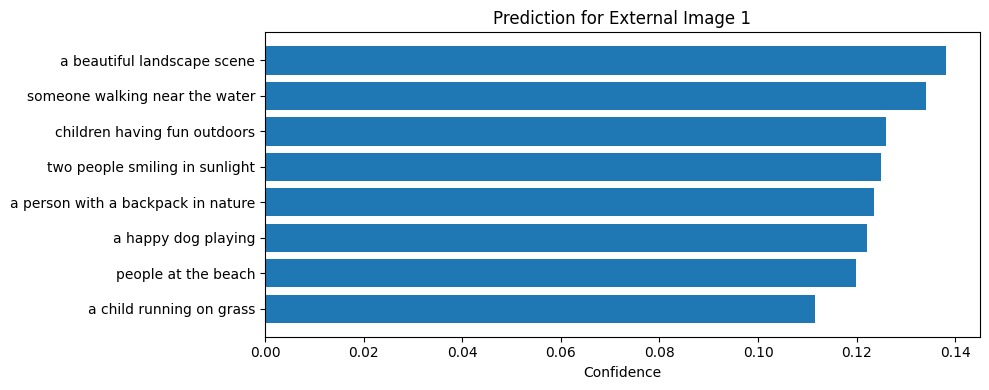


--- Skipping External Image 2 (https://images.unsplash.com/photo-1508919801845-fc2ae1bc1d1d) due to error: 404 Client Error: Not Found for url: https://images.unsplash.com/photo-1508919801845-fc2ae1bc1d1d ---

--- External Image 3 ---


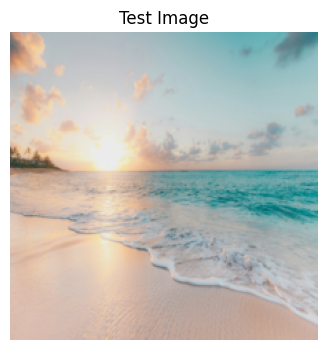

Prediction for External Image 3
----------------------------------------
someone walking near the water           -> 0.1593
people at the beach                      -> 0.1535
two people smiling in sunlight           -> 0.1356
a beautiful landscape scene              -> 0.1226
a child running on grass                 -> 0.1181
a person with a backpack in nature       -> 0.1121
children having fun outdoors             -> 0.1021
a happy dog playing                      -> 0.0967


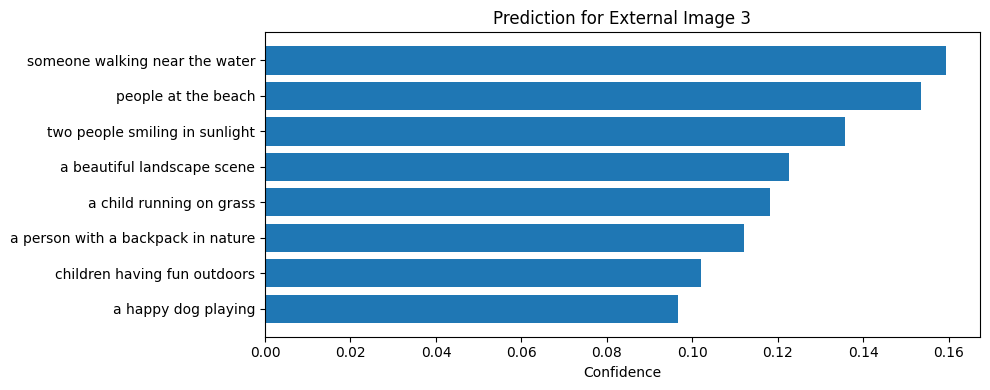

In [20]:
# Test on multiple random images from the validation loader
import random
import requests # Import requests
from io import BytesIO # Import BytesIO
from PIL import UnidentifiedImageError # Import UnidentifiedImageError


# Number of random images to test
num_samples = 5

# Get a batch of validation images
val_iter = iter(val_loader)
batch = next(val_iter)

# Pick random indices from this batch
indices_to_test = random.sample(range(len(batch['image'])), num_samples)

for idx in indices_to_test:
    img_tensor = batch['image'][idx]
    print(f"\n--- Image {idx+1} ---")
    show_image(img_tensor)  # visualize the image
    zero_shot_classify(model, img_tensor, custom_prompts, title=f"Prediction for Image {idx+1}")

# List of image URLs to test
test_image_urls = [
    "https://images.unsplash.com/photo-1507149833265-60c372daea22",  # dog
    "https://images.unsplash.com/photo-1508919801845-fc2ae1bc1d1d",  # child outdoors
    "https://images.unsplash.com/photo-1507525428034-b723cf961d3e",  # beach
]

for i, url in enumerate(test_image_urls, start=1):
    try: # Add try-except block to handle UnidentifiedImageError
        response = requests.get(url)
        response.raise_for_status()  # Raise an exception for bad status codes (4xx or 5xx)
        img = Image.open(BytesIO(response.content)).convert('RGB')
        transformed_img = img_transform(img)  # same preprocessing as training

        print(f"\n--- External Image {i} ---")
        show_image(transformed_img)  # visualize original
        zero_shot_classify(model, transformed_img, custom_prompts, title=f"Prediction for External Image {i}")
    except (requests.exceptions.RequestException, UnidentifiedImageError) as e: # Catch requests exceptions and UnidentifiedImageError
        print(f"\n--- Skipping External Image {i} ({url}) due to error: {e} ---")

# Conclusion
At the start of this project, my goal was to implement the CLIP architecture from scratch using the Flickr8k dataset. The initial plan was straightforward: load the dataset, build the dual-encoder architecture with pretrained ResNet-50 for images and DistilBERT for text, and train the model with a contrastive learning objective. This was intended to allow the model to learn a shared embedding space where semantically related images and captions are close together.

In the beginning, I worked on the core pipeline:

Data Preparation: Downloading, cleaning, and splitting the Flickr8k dataset into training, validation, and testing sets, while applying image transformations and text tokenization.

Model Implementation: Building the CLIP model with an image encoder, text encoder, projection layers, and a learnable temperature parameter.

Training: Implementing a training loop with cosine learning rate scheduling and monitoring both loss and accuracy to track convergence.

Initially, the zero-shot classification step used generic prompts (e.g., "a photo of a dog", "a photo of a person"). While this worked, it revealed a limitation: the prompts were too simple, which limited the model’s ability to capture nuanced relationships between the text descriptions and the image content.

To address this limitation, I implemented hard prompting. This approach uses richer, more descriptive, and context-specific prompts (e.g., "a person with a backpack in nature" instead of "a person"). This change provided the model with more semantic information in the text embeddings, which improved its ability to correctly match images with the intended meaning behind the prompt.

After adding hard prompting:

The zero-shot results became more precise — predictions were more aligned with the fine details in the images.

I also created visualizations (bar charts) to show the confidence scores for each class, making the evaluation more interpretable.

I tested both generic and hard prompts on sample images to compare their effects.

Key Learnings from this project:

Prompt engineering matters: the quality and specificity of text prompts can significantly impact zero-shot classification performance.

Model interpretability improves with visualization: plotting confidence scores made it easier to evaluate the model’s strengths and weaknesses.

End-to-end pipeline design: from dataset preparation to evaluation, every stage impacts the final output, and small improvements in one stage can have noticeable effects on the whole system.

Experimentation is essential:  starting simple, identifying limitations, and iterating with new ideas (like hard prompting) can meaningfully improve results.

In summary, this project started as a standard CLIP implementation but evolved into a more experiment-driven workflow where I learned the value of prompt design and careful evaluation. The experience reinforced the importance of iteration and thoughtful engineering in building effective AI systems.

## 📝 Evaluation Criteria

Your homework will be evaluated based on:

1. **Implementation Correctness (40%)**
   - Proper dual-encoder CLIP architecture
   - Correct contrastive loss implementation
   - Working training loop with proper optimization
   - Accurate zero-shot classification function

2. **Model Performance (30%)**
   - Convergence during training (decreasing loss)
   - Reasonable accuracy on validation set
   - Meaningful zero-shot classification results
   - Effective image-text alignment in embedding space

3. **Code Quality and Analysis (30%)**
   - Clean, readable code with appropriate structure
   - Comprehensive visualizations and analysis
   - Understanding of multimodal learning concepts
   - Insightful interpretation of results

## 🎯 Expected Outcomes
- Train loss should decrease and stabilize
- Validation accuracy should improve over epochs
- Zero-shot classification should show reasonable predictions
- Similarity matrices should reflect semantic relationships
- Model should demonstrate understanding of image-text correspondence